# Rajasthan school education: district analysis (UDISE+ 2024-25 and 2025-26)

**Question:** which districts are falling behind on school infrastructure and teachers, and is that
linked to girls staying in secondary school?

**Data:** the gold layer of this project's pipeline (`data/gold/udise.duckdb`): district marts for the
rankings, and the star schema for the school-level model and the matched-school comparison. All 41
districts, about 1.06 lakh schools a year. Every figure below is produced by `analysis/` from that
database; school-level rows stay in memory and only district-level results and model coefficients are
shown or saved.

**How to read the findings:** they describe patterns and associations in administrative data. None of
them is a causal estimate. UDISE+ is self-reported by schools (see `DATA_QUALITY_LOG.md`).

Source: UDISE+, Ministry of Education, Government of India.

In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display
from analysis import data as D, run

pd.set_option("display.precision", 3)
numbers = run.build()                      # writes reports/figures/*.png and reports/analysis/*.csv
FIG = ROOT / "reports" / "figures"
TAB = ROOT / "reports" / "analysis"
numbers["state_2025_26"]

{'schools': 106167.0,
 'enrolment': 14954579.0,
 'teachers': 792524.0,
 'pct_single_teacher': 6.724,
 'avg_infra_index': 79.764,
 'ptr': 18.87}

## A1. Which districts are falling behind?

Three district indicators for 2025-26 (schools with students in classes 1-12):
- **Infrastructure index (0-100):** for each school, the share of 8 basic facilities it has (electricity,
  safe water, girls' toilet, handwash, library, ramp, internet, computer), averaged over the district's
  schools. Playground is left out: its reported availability dropped by more than 5 points in 24 districts
  in one year, a reporting change rather than a real loss.
- **Single-teacher schools (%)**
- **Pupil-teacher ratio (PTR)**: students in classes 1-12 per teacher.

In [2]:
rank = pd.read_csv(TAB / "a1_district_rankings_2025-26.csv")
print("Bottom 10 on infrastructure (rank 1 = worst):")
rank.head(10)[["district", "avg_infra_index", "pct_single_teacher", "ptr", "rank_pct_single_teacher", "rank_ptr"]]

Bottom 10 on infrastructure (rank 1 = worst):


,district,avg_infra_index,pct_single_teacher,ptr,rank_pct_single_teacher,rank_ptr
0,BANSWARA,64.492,16.522,20.659,3,11
1,SALUMBAR,66.787,15.781,22.258,4,5
2,PRATAPGARH,68.012,19.909,21.625,1,8
3,BARAN,68.486,9.280,17.718,10,32
4,DUNGARPUR,70.107,14.995,19.465,5,15
5,UDAIPUR,72.141,10.479,19.444,8,16
6,JAISALMER,74.869,16.876,20.039,2,12
7,PHALODI,75.173,10.572,22.209,7,6
8,DEEG,76.147,3.453,20.724,32,10
9,DAUSA,76.779,6.070,18.104,15,30


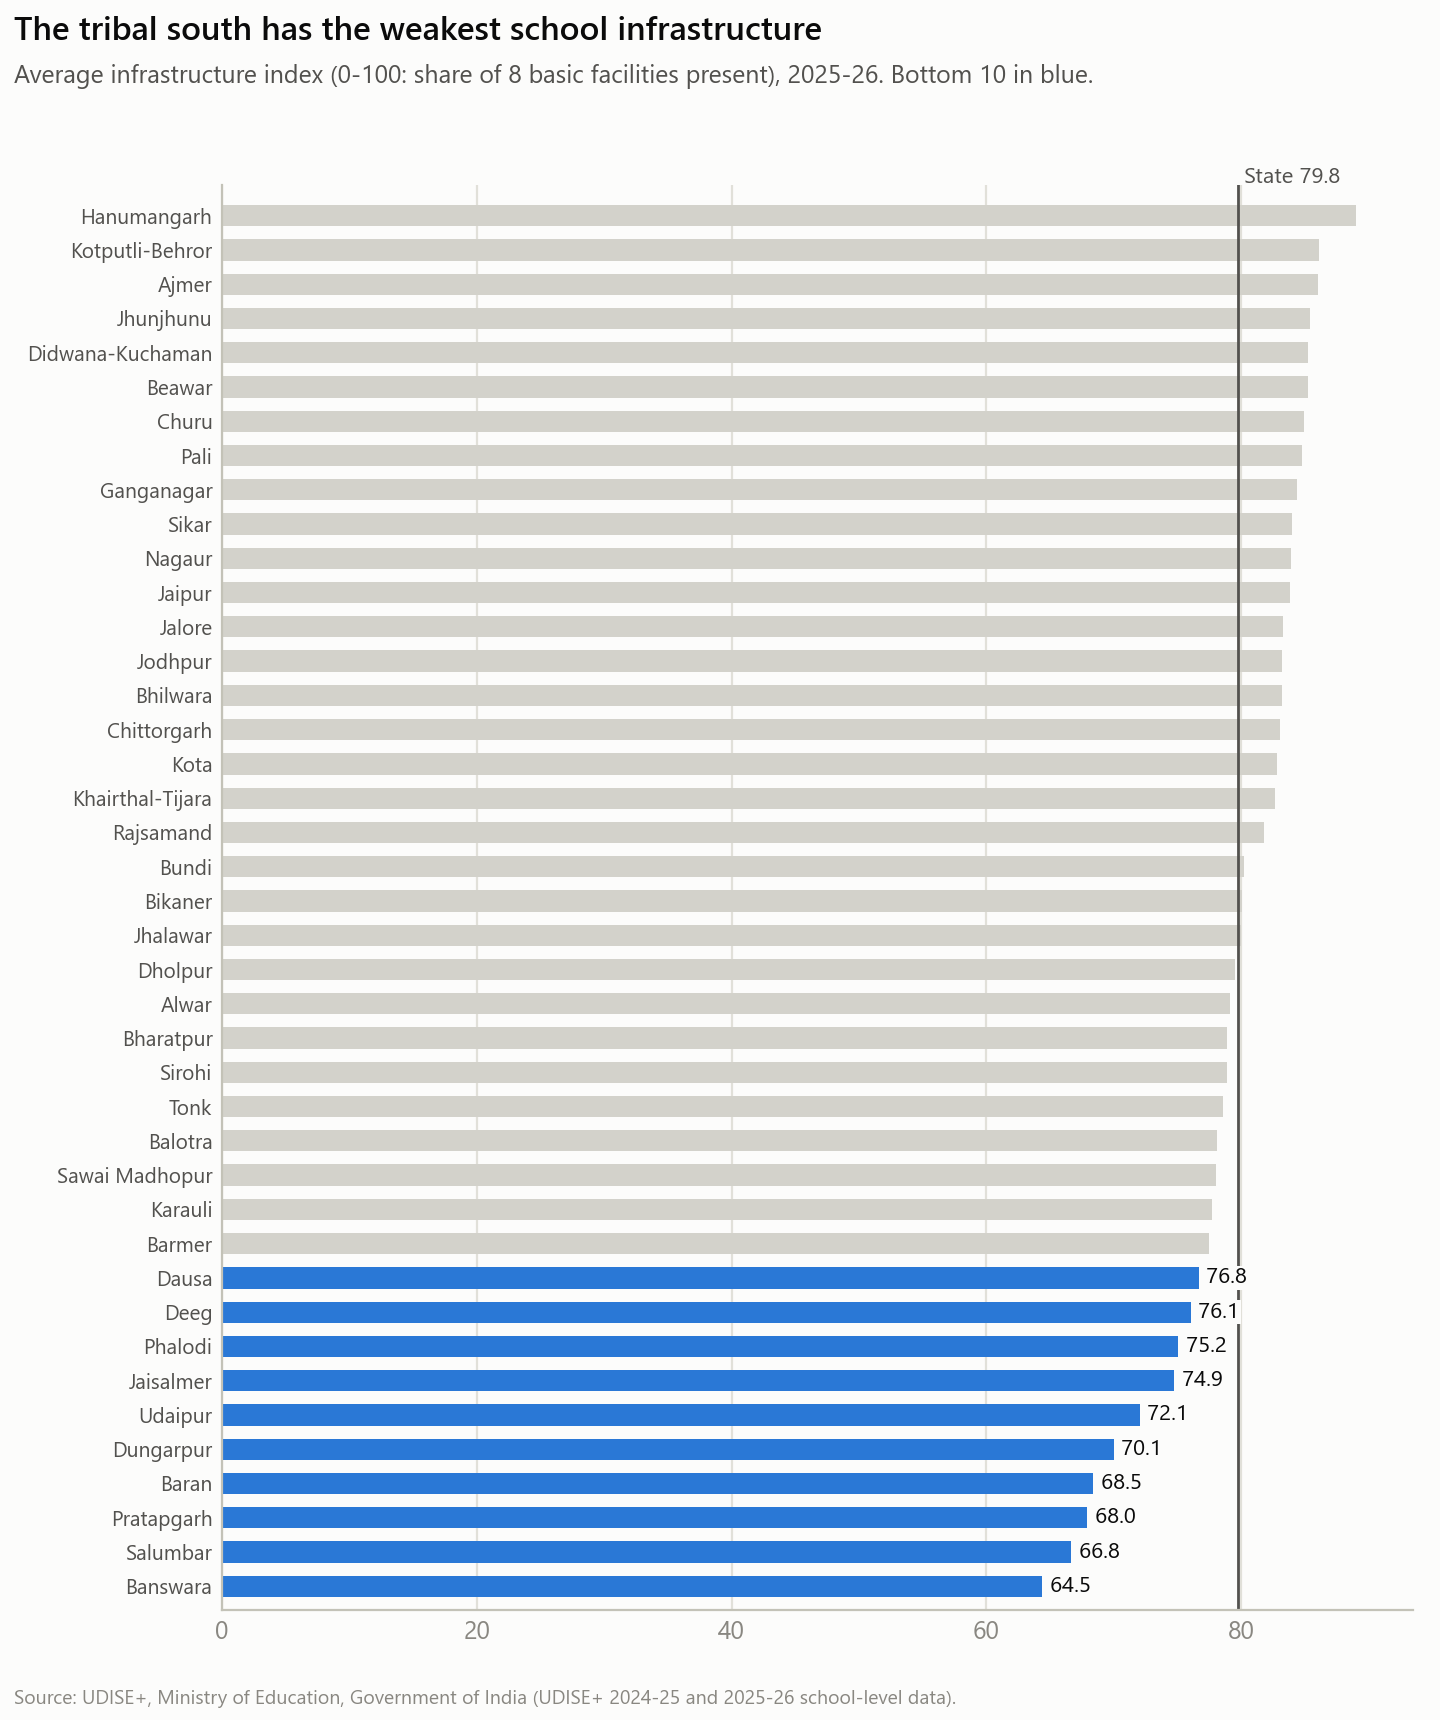

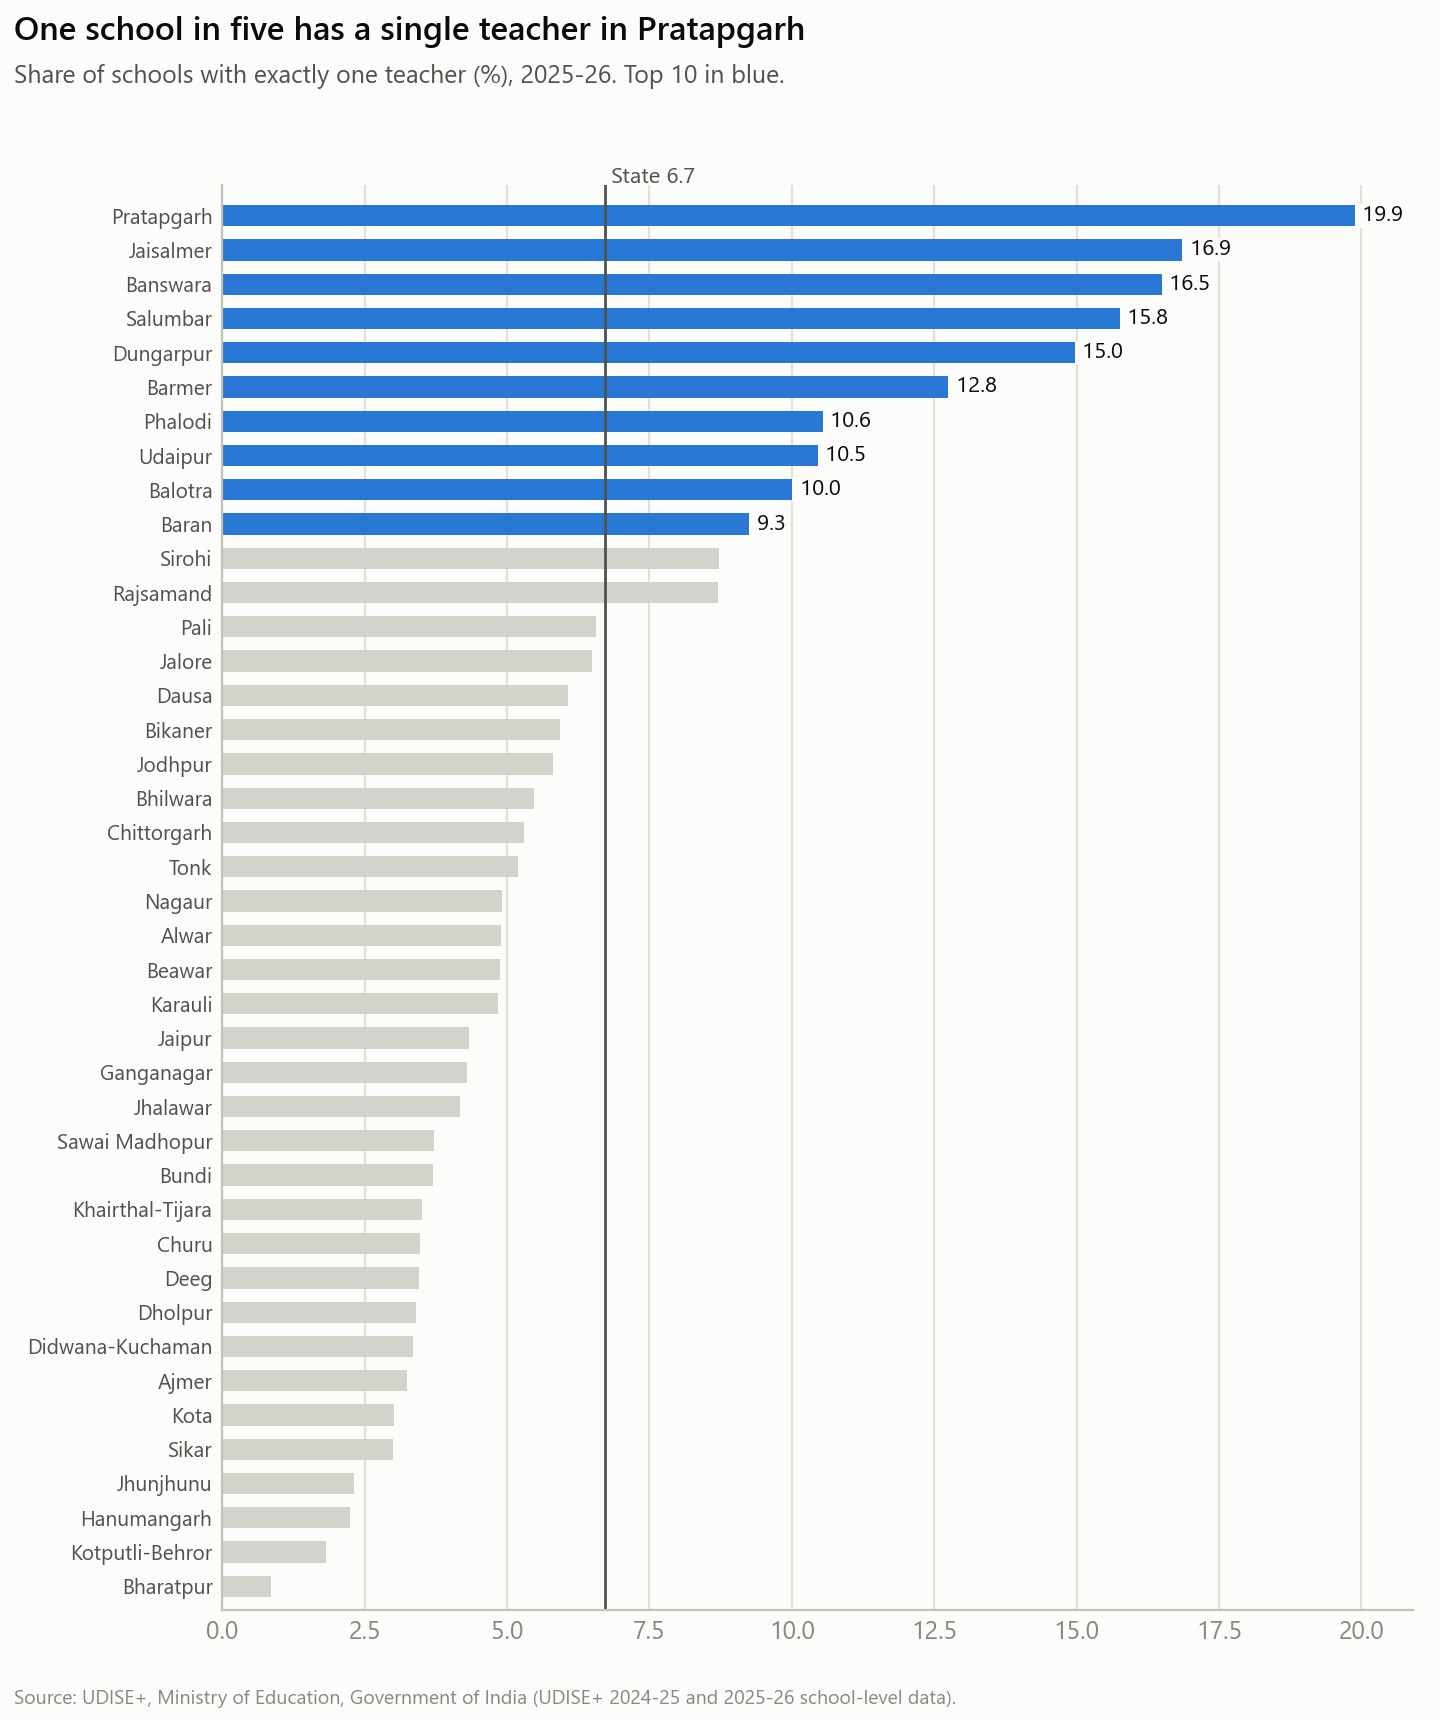

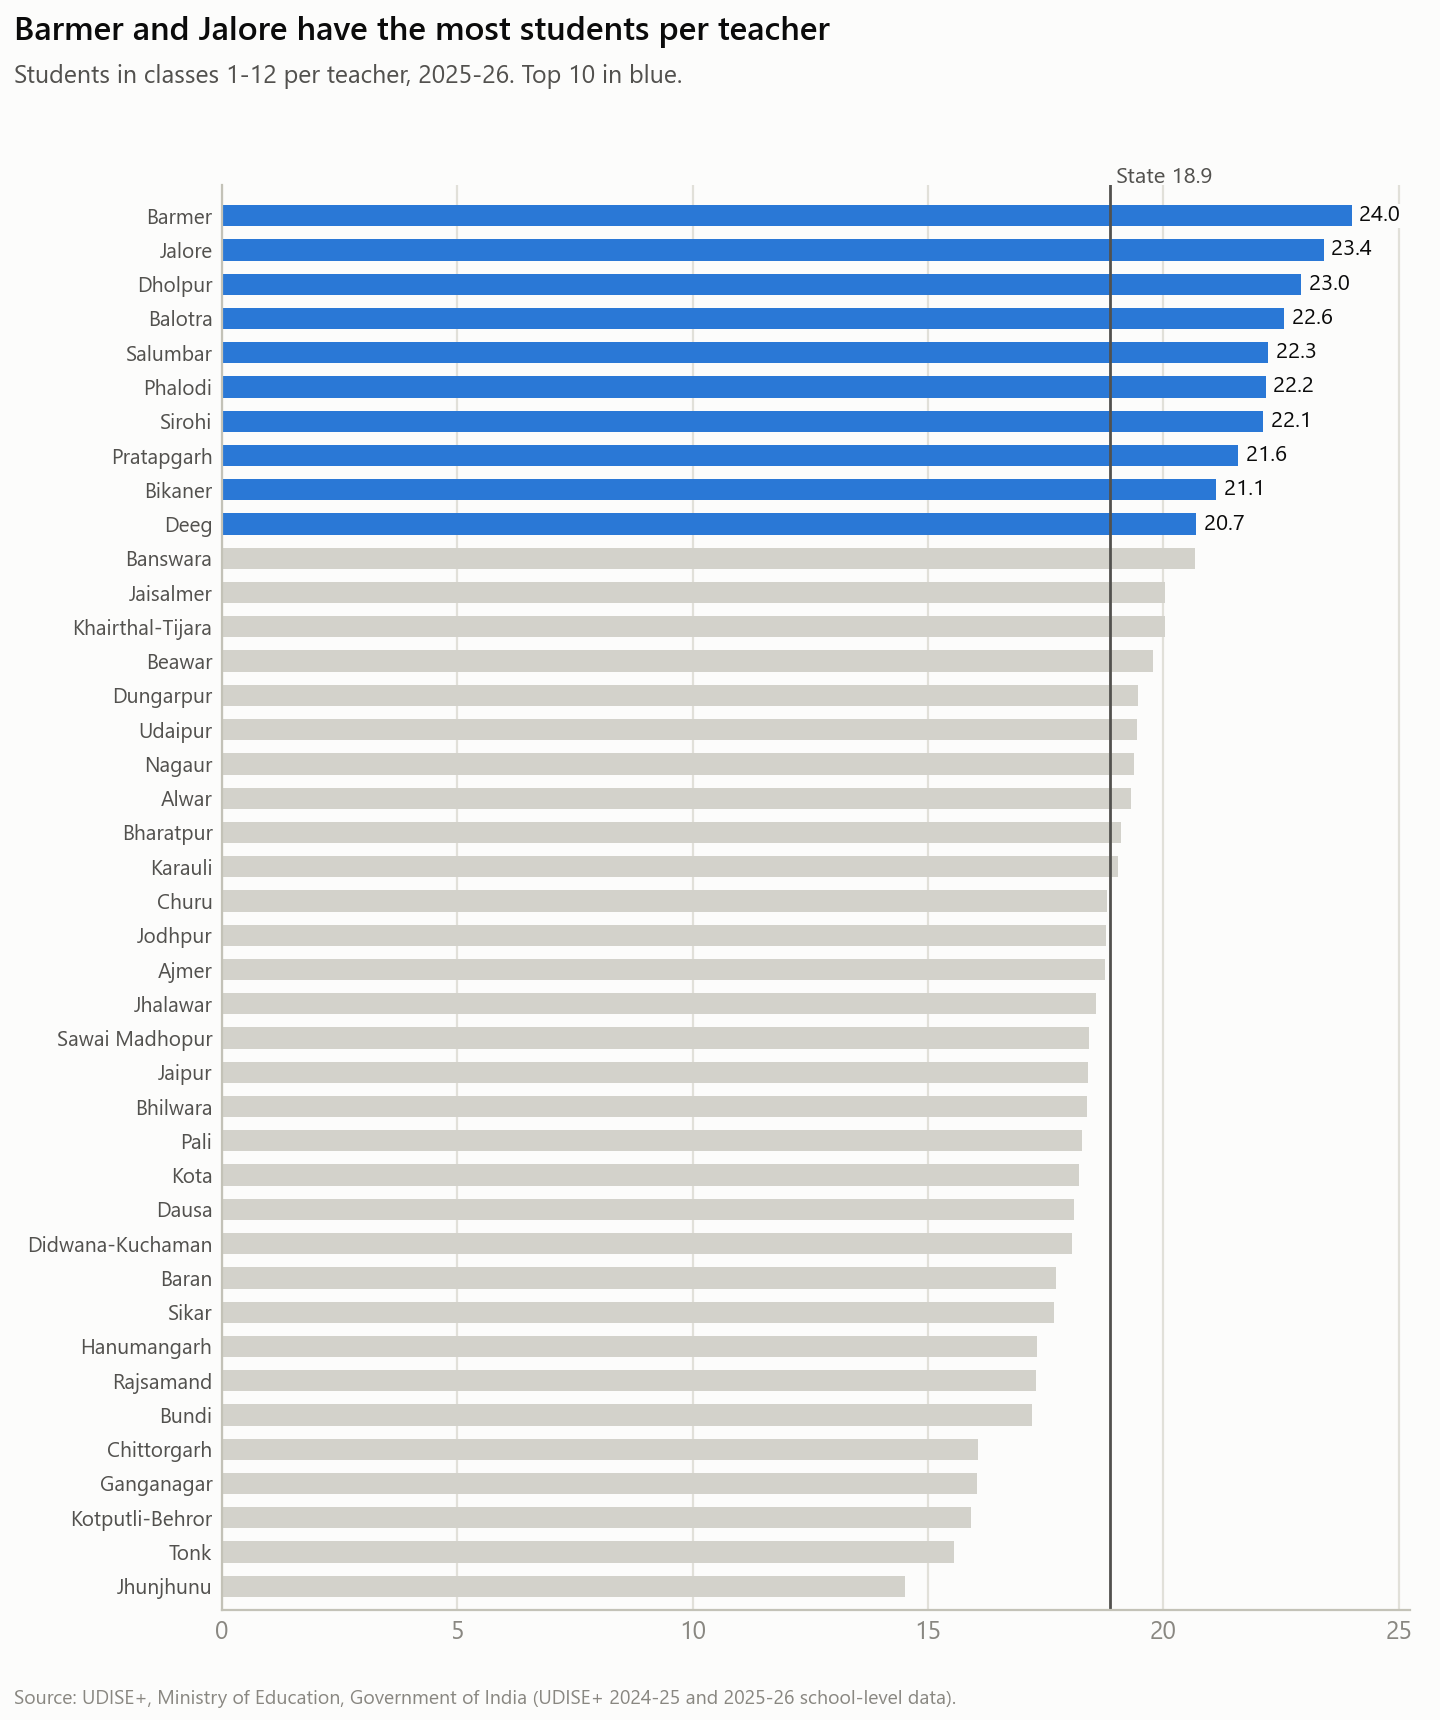

In [3]:
display(Image(FIG / "a1_infrastructure_index.png", width=720))
display(Image(FIG / "a1_single_teacher.png", width=720))
display(Image(FIG / "a1_ptr.png", width=720))

**Reading.** Three tribal-majority districts of the south (Banswara, Salumbar, Pratapgarh) have the
weakest infrastructure in the state (Baran and Dungarpur follow), and together with Dungarpur they are
four of the five districts with the most single-teacher schools. Infrastructure and teacher shortages overlap in the same places. Pupil-teacher
ratios are highest in the west (Barmer, Jalore, Balotra, Phalodi) and in Dholpur.

## A2. Girls in secondary school: three different patterns

Two measures, per district:
- **Girls' retention gap** = girls' share of students in classes 9-12 minus their share in classes 1-5.
  Comparing a share with a share cancels out differences in the child sex ratio between districts.
  Negative means girls make up a smaller part of senior classes than of primary classes.
- **Progression ratio** (for boys and girls separately) = students per grade in classes 9-12 divided by
  students per grade in classes 1-5. It is not a cohort dropout rate: it mixes dropout, migration and
  changes in cohort size, which is why boys' and girls' ratios are read together.

The gap is negative in 17 of the 41 districts and positive in 24. A negative gap can come from very
different situations. The districts are grouped with simple,
stated thresholds (`analysis/data.py`, `patterns`): girls leaving (gap at most -0.02 and boys'
ratio below 1), boys moving in (gap at most -0.01 and boys' ratio above 1), and boys leaving (gap at
least +0.015 in a majority-ST district). The thresholds are descriptive choices, not tests.

In [4]:
a2 = pd.read_csv(TAB / "a2_girls_secondary_2025-26.csv")
a2[a2["pattern"] != "other"]

,district,pattern,girls_share_primary,girls_share_sec_plus,girls_retention_gap,boys_progression,girls_progression,st_share
0,SIKAR,boys moving in,0.471,0.417,-0.054,1.494,1.201,0.034
1,JAISALMER,girls leaving,0.469,0.431,-0.039,0.599,0.512,0.078
2,BARMER,girls leaving,0.471,0.445,-0.026,0.725,0.652,0.059
3,KOTA,boys moving in,0.474,0.452,-0.022,1.019,0.933,0.097
5,JHUNJHUNU,boys moving in,0.472,0.459,-0.013,1.085,1.029,0.022
30,UDAIPUR,boys leaving (tribal south),0.474,0.490,0.016,0.711,0.759,0.542
32,BANSWARA,boys leaving (tribal south),0.477,0.494,0.018,0.742,0.795,0.829
35,DUNGARPUR,boys leaving (tribal south),0.478,0.501,0.023,0.865,0.949,0.804
36,SALUMBAR,boys leaving (tribal south),0.483,0.508,0.025,0.764,0.842,0.785
40,PRATAPGARH,boys leaving (tribal south),0.480,0.509,0.029,0.733,0.825,0.730


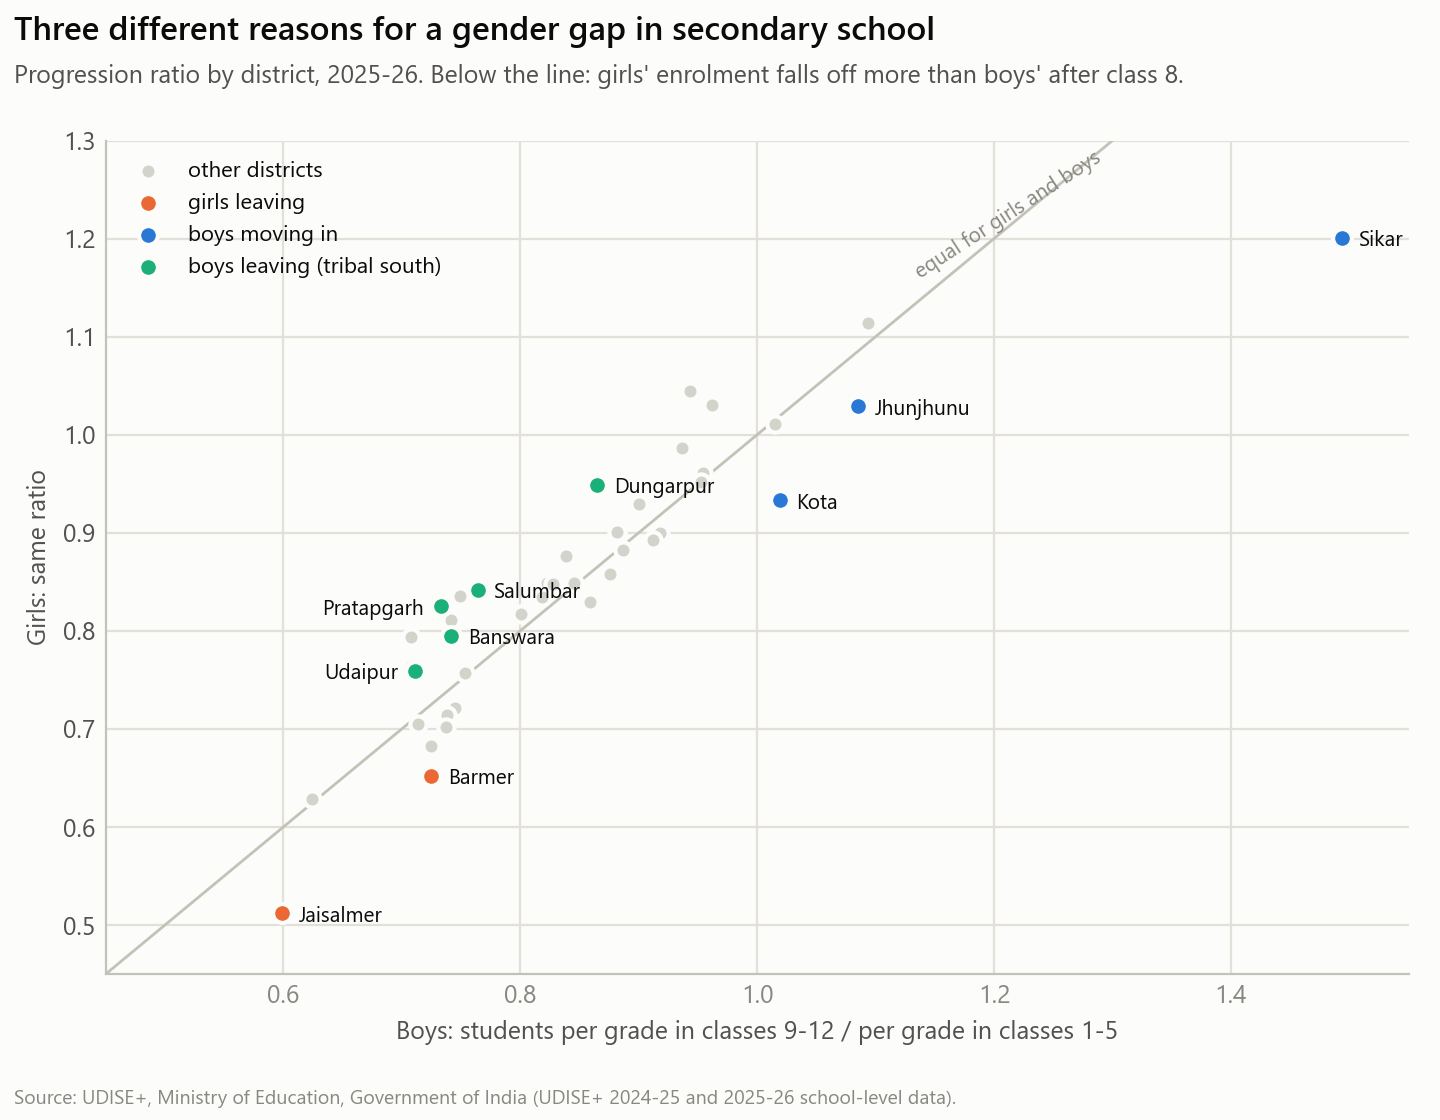

In [5]:
display(Image(FIG / "a2_progression.png", width=720))

**Reading.**
- **Girls leaving (Jaisalmer, Barmer):** both sexes fall off after class 8, girls much more: Jaisalmer has
  only about half as many girls per grade in classes 9-12 as in classes 1-5 (ratio 0.51), the lowest in the state.
- **Boys moving in (Sikar, Kota, Jhunjhunu):** the gap is negative because *boys* are added, not because
  girls leave. Sikar has 1.49 boys per grade in classes 9-12 for every boy per grade in classes 1-5, which
  is only possible with boys arriving from elsewhere (Sikar and Kota are coaching hubs). Girls' ratios are
  high too.
- **Boys leaving (tribal south):** the gap is positive because boys leave more than girls (boys' ratios
  0.71-0.87). This fits seasonal labour migration of adolescent boys from this region, but the data
  cannot show why boys leave; it is a hypothesis to check with field partners.

In [6]:
sector = pd.read_csv(TAB / "a2_girls_share_by_sector_2025-26.csv")
gap = sector.pivot(index="district", columns="sector", values="girls_retention_gap") * 100
gap["difference (pp)"] = gap["Non-government"] - gap["Government"]
print("Districts where the gap is lower in non-government than government schools:",
      int((gap["difference (pp)"] < 0).sum()), "of", len(gap))
gap.loc[a2.loc[a2["pattern"] != "other", "district"]].round(2)

Districts where the gap is lower in non-government than government schools: 41 of 41


sector,Government,Non-government,difference (pp)
district,,,
SIKAR,1.86,-8.30,-10.16
JAISALMER,-4.71,-8.12,-3.41
BARMER,0.74,-10.70,-11.44
KOTA,2.14,-6.05,-8.19
JHUNJHUNU,-0.57,-2.86,-2.29
UDAIPUR,2.78,-1.52,-4.30
BANSWARA,0.66,-1.62,-2.28
DUNGARPUR,1.24,-1.74,-2.98
SALUMBAR,2.10,-3.47,-5.57


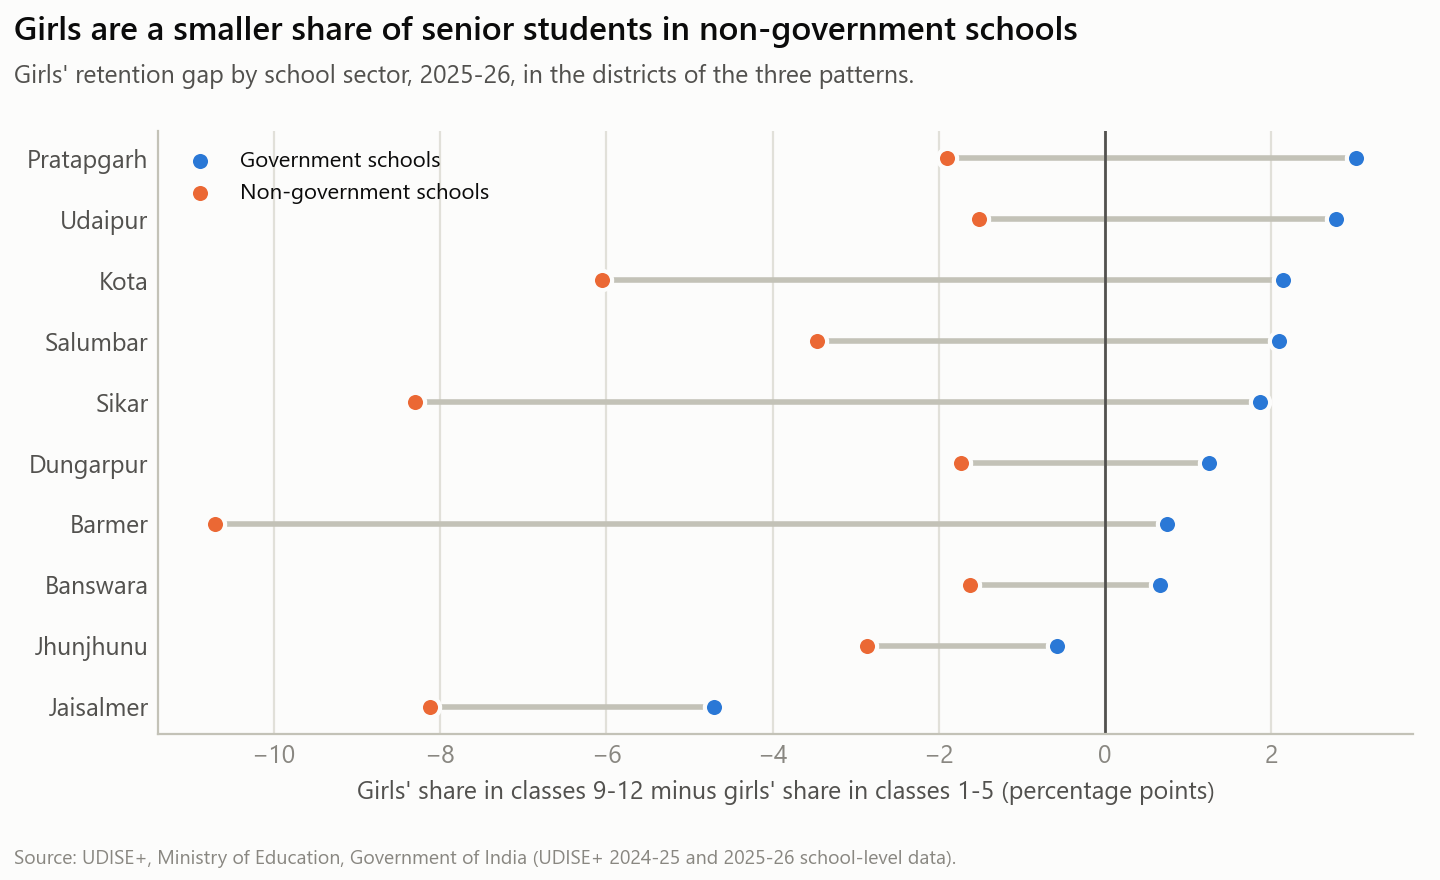

In [7]:
display(Image(FIG / "a2_sector.png", width=720))

**Reading.** In all 41 districts, the girls' retention gap is lower (worse for girls) in non-government
(mostly private, fee-charging) schools than in government schools; the table shows the pattern districts. Where families pay,
they appear to pay more often for boys' senior schooling; government schools carry most girls through
classes 9-12.

## A3. School-level model: what goes with a higher share of girls in classes 9-12?

**Sample:** co-educational schools with at least 20 students in classes 9-12 in 2025-26 (girls-only and
boys-only schools would dominate any share-of-girls model). **Outcome:** girls' share of the school's
students in classes 9-12. **Explanatory variables:** a functional girls' toilet; number of teachers (log);
an index of the 7 other facilities; urban location; management group. **District fixed effects** compare
schools only with other schools in the same district, so district-wide differences (sex ratio,
migration, culture) do not drive the result. Standard errors are clustered by district (41 clusters).
A second specification adds school category (which classes the school teaches).

In [8]:
coefs = pd.read_csv(TAB / "a3_regression_coefficients.csv")
print(numbers["regression"]["facts"])
coefs.round(2)

{'main': {'n_schools': 29479, 'r_squared': np.float64(0.229), 'clusters': 41}, 'with school category': {'n_schools': 29479, 'r_squared': np.float64(0.238), 'clusters': 41}}


,spec,term,coef_pp,ci_low_pp,ci_high_pp,p_value
0,main,Functional girls' toilet (yes vs no),1.71,1.15,2.28,0.00
1,main,Teachers (log; +1 = about 2.7x as many),-1.89,-2.51,-1.27,0.00
2,main,Other facilities index (+10 points),-0.10,-0.24,0.04,0.17
3,main,Urban (vs rural),-1.53,-2.08,-0.98,0.00
4,main,Private unaided (vs state govt),-13.26,-14.71,-11.82,0.00
5,with school category,Functional girls' toilet (yes vs no),1.57,1.05,2.09,0.00
6,with school category,Teachers (log; +1 = about 2.7x as many),-2.08,-2.72,-1.44,0.00
7,with school category,Other facilities index (+10 points),-0.09,-0.22,0.05,0.20
8,with school category,Urban (vs rural),-1.27,-1.79,-0.74,0.00
9,with school category,Private unaided (vs state govt),-13.03,-14.41,-11.66,0.00


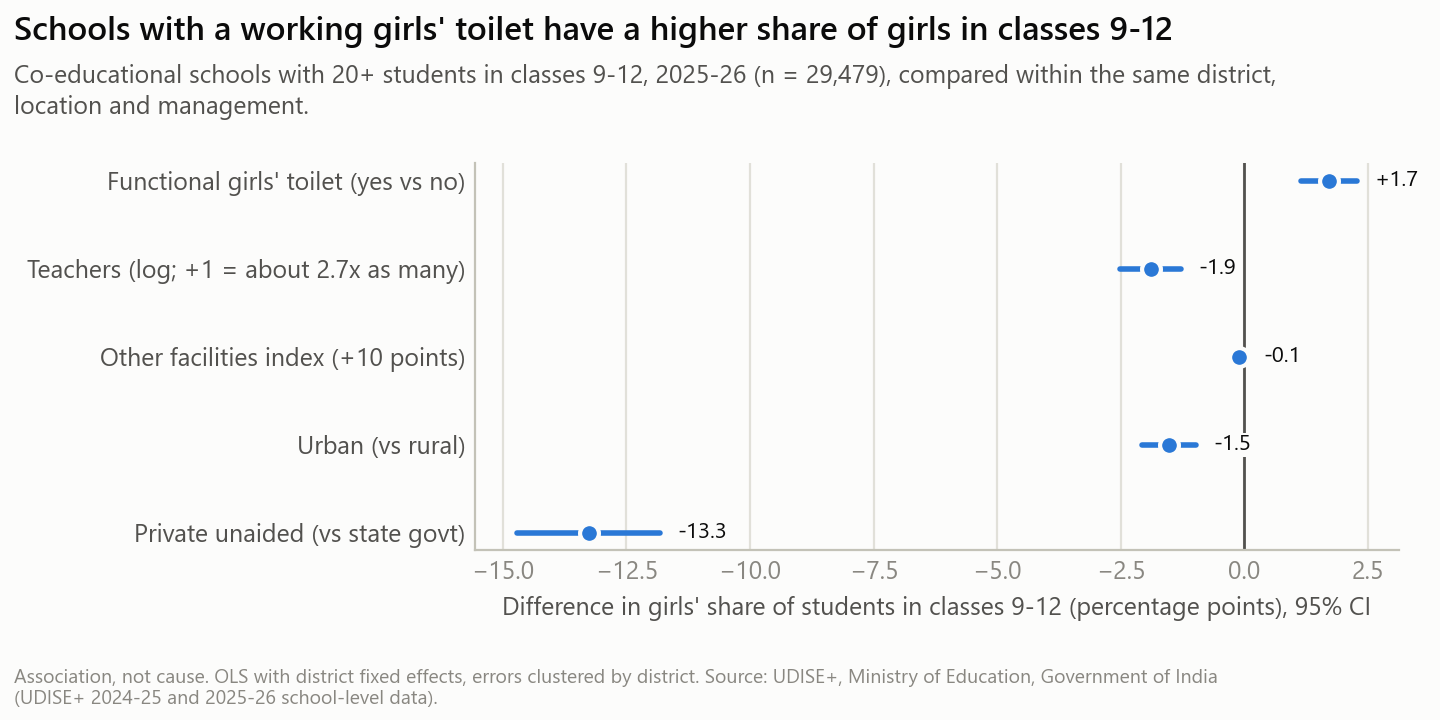

In [9]:
display(Image(FIG / "a3_coefficients.png", width=720))

**Reading.**
- Schools with a functional girls' toilet have a girls' share about **1.7 percentage points higher**
  (95% CI about 1.2 to 2.3) than comparable schools in the same district without one; about 1.6 points
  when school category is also controlled.
- **Private unaided** schools have a girls' share about **13 points lower** than state-government schools
  in the same district: the clearest pattern in the data, and consistent with A2.
- The 7 other facilities show no association once the girls' toilet is in the model.
- More teachers goes with a slightly lower girls' share. Teachers are not likely to push girls out;
  larger senior schools (often with science and commerce streams) may draw more boys. This shows what an
  observational model cannot separate.

**Caveats.** Associations, not effects: a school may get a girls' toilet *because* it has more girls
(reverse causality), and schools with toilets may differ in ways not measured here. The data is
self-reported. The R-squared is about 0.23: most of the variation between schools is not explained.

## A4. Year-on-year change, same schools only

Comparing district totals across years mixes real change with schools opening, closing or moving
district (189 schools moved, 180 of them from Alwar to Kotputli-Behror). So this comparison uses only
schools present in both years (matched on the UDISE+ school code), each counted in its 2025-26
district in both years.

In [10]:
a4 = pd.read_csv(TAB / "a4_single_teacher_change_matched.csv")
print(numbers["matched_single_teacher"]["schools"], "matched schools; state change (pp):",
      numbers["matched_single_teacher"]["state_change_pp"])
a4.head(8)[["district", "schools_2025", "pct_single_teacher_2024", "pct_single_teacher_2025", "change_pp",
            "teachers_change_pct"]]

105418 matched schools; state change (pp): 1.047


,district,schools_2025,pct_single_teacher_2024,pct_single_teacher_2025,change_pp,teachers_change_pct
0,JAISALMER,1736.0,12.270,16.705,4.435,-2.641
1,BARMER,3746.0,8.436,12.787,4.351,-2.745
2,PHALODI,1613.0,6.262,10.601,4.340,-1.141
3,RAJSAMAND,2162.0,5.365,8.418,3.053,-2.697
4,BALOTRA,2149.0,7.166,9.958,2.792,-3.542
5,JALORE,2752.0,4.397,6.504,2.108,-2.465
6,CHITTORGARH,2482.0,3.263,5.278,2.015,-1.653
7,SIROHI,1378.0,6.894,8.781,1.887,-0.846


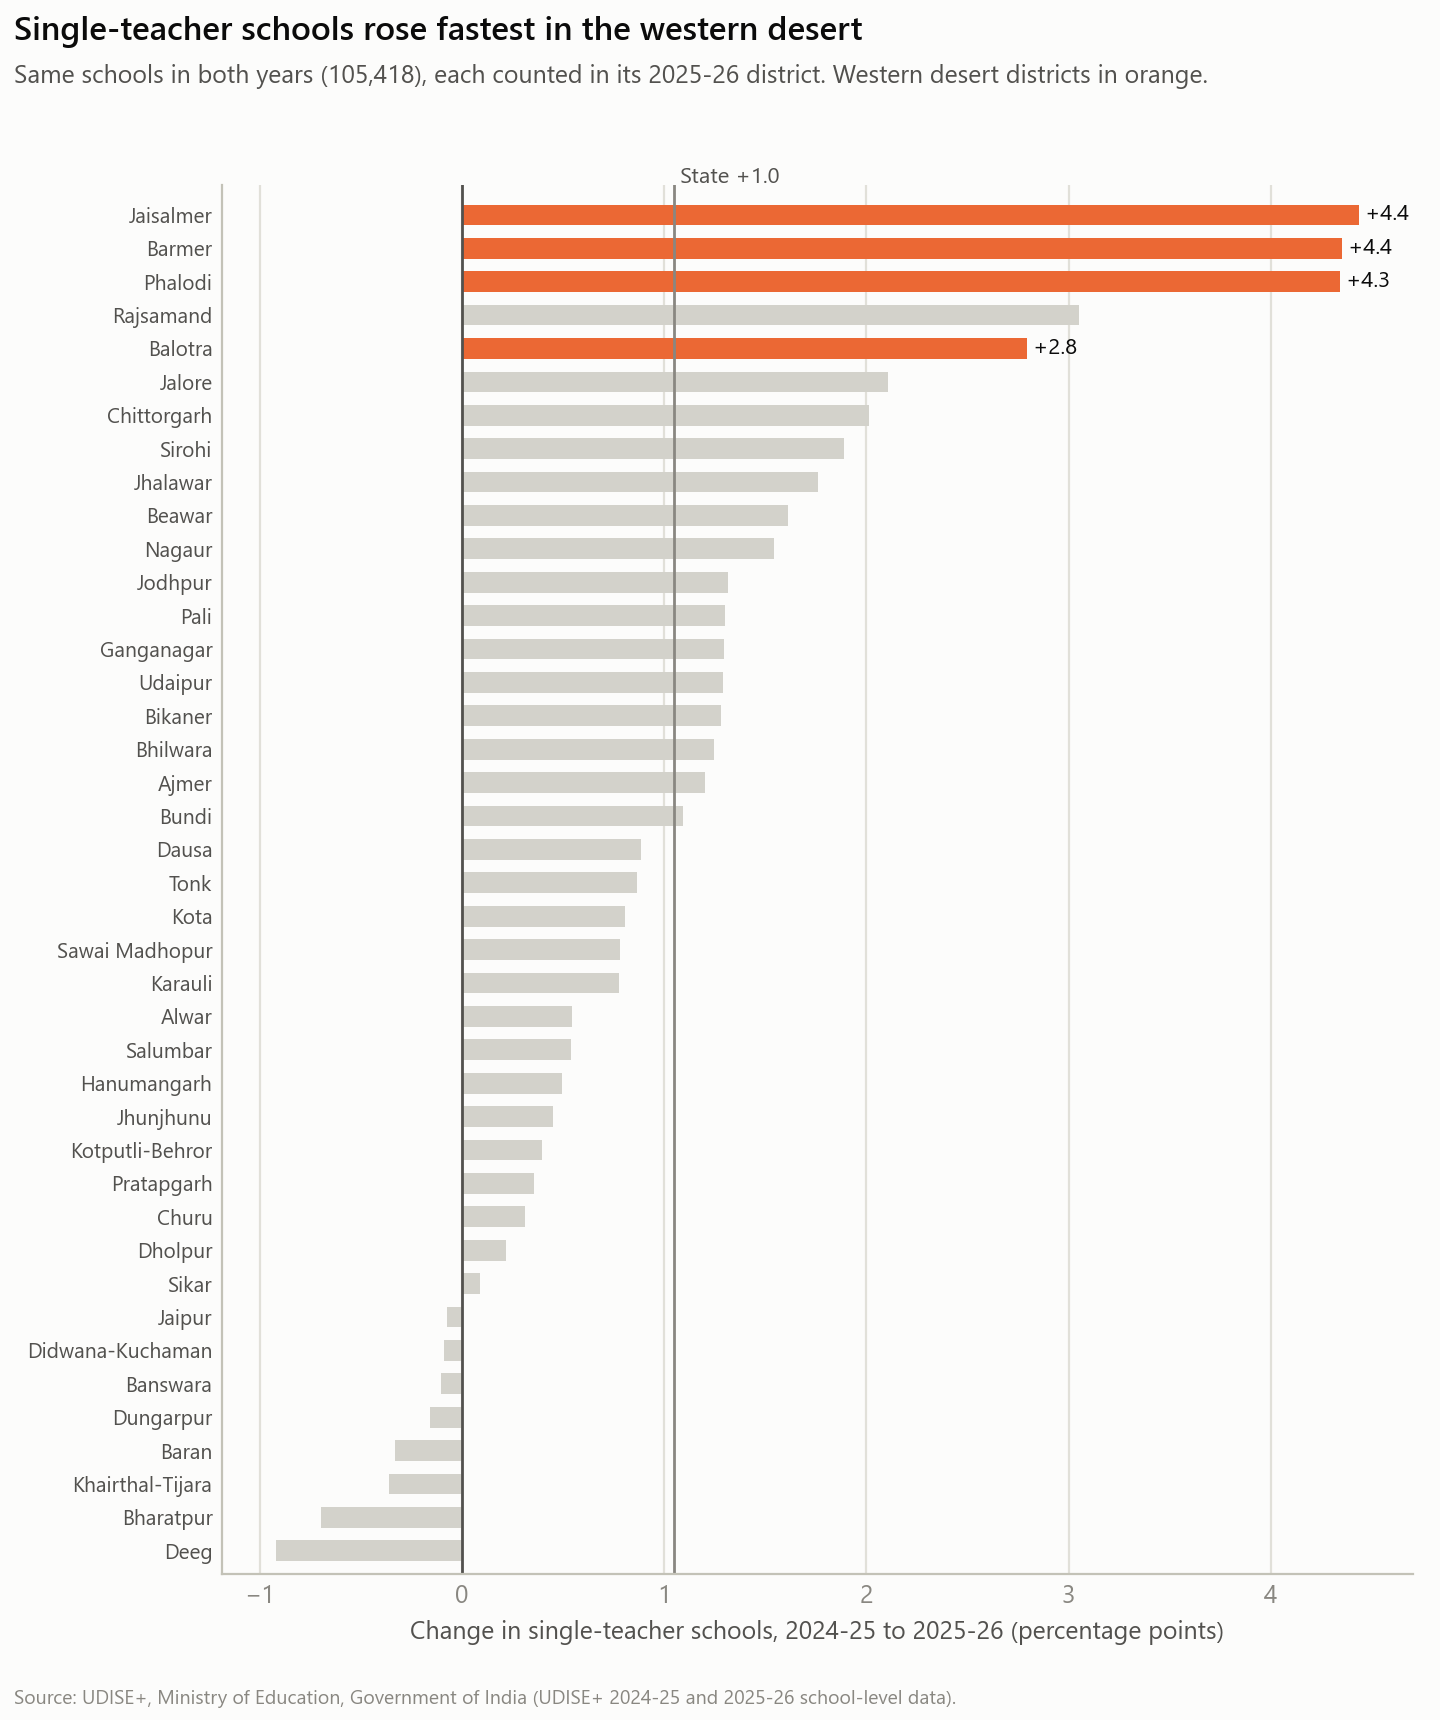

In [11]:
display(Image(FIG / "a4_single_teacher_change.png", width=720))

**Reading.** Among the same schools, the share with a single teacher rose by about 1 point state-wide,
but by over 4 points in Jaisalmer, Barmer and Phalodi, and by 2.8 in Balotra. Jaisalmer, Barmer and
Balotra are also among the 6 districts that lost more than 2% of their teachers in these same schools
(the median district: no change; state: -0.08%). Combined with A2 (the lowest girls'
progression is in Jaisalmer; Barmer is third), the western desert is where staffing is worsening fastest.

## Summary
1. **The tribal south is furthest behind on infrastructure and teachers** (Banswara, Salumbar, Pratapgarh,
   with Dungarpur on single-teacher schools), yet its girls stay in school relatively better than its boys.
2. **The gender gap in secondary school has three different causes**: girls leaving (Jaisalmer, Barmer),
   boys arriving (Sikar, Kota), boys leaving (tribal south). One policy will not fit all three.
3. **Girls' toilets and government schools go with more girls in classes 9-12**; private schools with
   fewer. **Single-teacher schools are rising fastest in the western desert**, where girls already fall
   off most.

These findings are the basis of the policy brief (`docs/policy_brief.md`).